In [ ]:
import os, json, time, gc
import numpy as np, pandas as pd, torch, transformers
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/fever_project'
if not os.path.isdir(ROOT):
    raise FileNotFoundError(f'{ROOT} not found. Add the shared fever_project folder as a shortcut in My Drive.')
for d in ['data/evidence', 'data/processed', 'models', 'results', 'checkpoints', 'notebooks']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)

LABELS   = ['SUPPORTS', 'REFUTES', 'NOT ENOUGH INFO']
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
CONTRACT_COLS = ['id', 'claim', 'evidence', 'label', 'label_id', 'evidence_source', 'n_sent']

def check_contract(df, name='dataframe'):
    missing = [c for c in CONTRACT_COLS if c not in df.columns]
    assert not missing, f'{name}: missing columns {missing}'
    assert df['id'].is_unique, f'{name}: duplicate ids'
    assert df['label'].isin(LABELS).all(), f'{name}: unexpected label strings'
    assert (df['label'].map(label2id) == df['label_id']).all(), f'{name}: label_id does not match label'
    assert df['claim'].str.len().gt(0).all() and df['evidence'].str.len().gt(0).all(), f'{name}: empty claim or evidence'
    print(f'{name}: contract OK ({len(df)} rows)')

print('transformers', transformers.__version__, '| GPU:', torch.cuda.is_available())

Mounted at /content/drive
transformers 5.22.1 | GPU: True


In [ ]:
MODE = 'real'            # change to 'real' in the real evaluation task
MAX_LEN = 128           # must equal the training max length

CFG = {
    'toy':  dict(model_dir=f'{ROOT}/models/_toy_model',
                 val_pairs=f'{ROOT}/data/processed/_toy_val_pairs.parquet',
                 out_dir=f'{ROOT}/results/_toy'),
    'real': dict(model_dir=f'{ROOT}/models/distilbert-fever-v1',
                 val_pairs=f'{ROOT}/data/processed/val_pairs.parquet',
                 out_dir=f'{ROOT}/results'),
}[MODE]

assert 'test' not in os.path.basename(CFG['val_pairs']).lower(), 'Never evaluate on the test set in this phase.'
for k in ('model_dir', 'val_pairs'):
    assert os.path.exists(CFG[k]), f'Missing {k}: {CFG[k]}'
os.makedirs(CFG['out_dir'], exist_ok=True)
print('MODE:', MODE); print(json.dumps(CFG, indent=2))

MODE: real
{
  "model_dir": "/content/drive/MyDrive/fever_project/models/distilbert-fever-v1",
  "val_pairs": "/content/drive/MyDrive/fever_project/data/processed/val_pairs.parquet",
  "out_dir": "/content/drive/MyDrive/fever_project/results"
}


In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
from datasets import Dataset

tok   = AutoTokenizer.from_pretrained(CFG['model_dir'])
model = AutoModelForSequenceClassification.from_pretrained(CFG['model_dir'])
saved = {int(k): v for k, v in model.config.id2label.items()}
assert [saved[i] for i in range(3)] == LABELS, f'Label order in the saved model differs: {saved}'

val_pairs = pd.read_parquet(CFG['val_pairs']).reset_index(drop=True)
check_contract(val_pairs, 'val_pairs')

val_ds = Dataset.from_pandas(val_pairs[['claim', 'evidence', 'label_id']].rename(columns={'label_id': 'labels'}),
                             preserve_index=False)
val_ds = val_ds.map(lambda b: tok(b['claim'], b['evidence'], truncation=True, max_length=MAX_LEN),
                    batched=True, remove_columns=['claim', 'evidence'])
assert (np.array(val_ds['labels']) == val_pairs['label_id'].values).all()
print('validation examples:', len(val_ds))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

val_pairs: contract OK (9997 rows)


Map:   0%|          | 0/9997 [00:00<?, ? examples/s]

validation examples: 9997


In [ ]:
from torch.utils.data import DataLoader

USE_FP16 = False                                   # official numbers: full precision, same as the Trainer's evaluation
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model.to(device).eval()
loader = DataLoader(val_ds, batch_size=64, shuffle=False,
                    collate_fn=DataCollatorWithPadding(tok, pad_to_multiple_of=8))
all_logits, all_labels = [], []
t0 = time.time()
with torch.no_grad():
    for batch in loader:
        batch.pop('token_type_ids', None)          # DistilBERT does not use segment ids
        labels = batch.pop('labels')
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(USE_FP16 and device == 'cuda')):
            out = model(**batch).logits
        all_logits.append(out.float().cpu()); all_labels.append(labels)

logits = torch.cat(all_logits)
y_true = torch.cat(all_labels).numpy()
y_pred = logits.argmax(-1).numpy()
val_loss = torch.nn.functional.cross_entropy(logits, torch.tensor(y_true)).item()
assert (y_true == val_pairs['label_id'].values).all(), 'prediction order does not match val_pairs'
print(f'predicted {len(y_pred)} examples in {time.time() - t0:.1f}s | validation loss: {val_loss:.4f}')

predicted 9997 examples in 33.7s | validation loss: 0.5030


{
  "mode": "real",
  "n_val": 9997,
  "val_loss": 0.5029853582382202,
  "val_accuracy": 0.8361508452535761,
  "val_macro_precision": 0.8367176925884056,
  "val_macro_recall": 0.8361341387816356,
  "val_macro_f1": 0.8347263807543035,
  "majority_class_baseline_accuracy": 0.3334000200060018
}
                 precision    recall  f1-score   support

       SUPPORTS     0.8257    0.9226    0.8715      3333
        REFUTES     0.8448    0.8332    0.8390      3333
NOT ENOUGH INFO     0.8396    0.7526    0.7937      3331

       accuracy                         0.8362      9997
      macro avg     0.8367    0.8361    0.8347      9997
   weighted avg     0.8367    0.8362    0.8347      9997

Confusion matrix (rows = true, columns = predicted):
[[3075   88  170]
 [ 247 2777  309]
 [ 402  422 2507]]


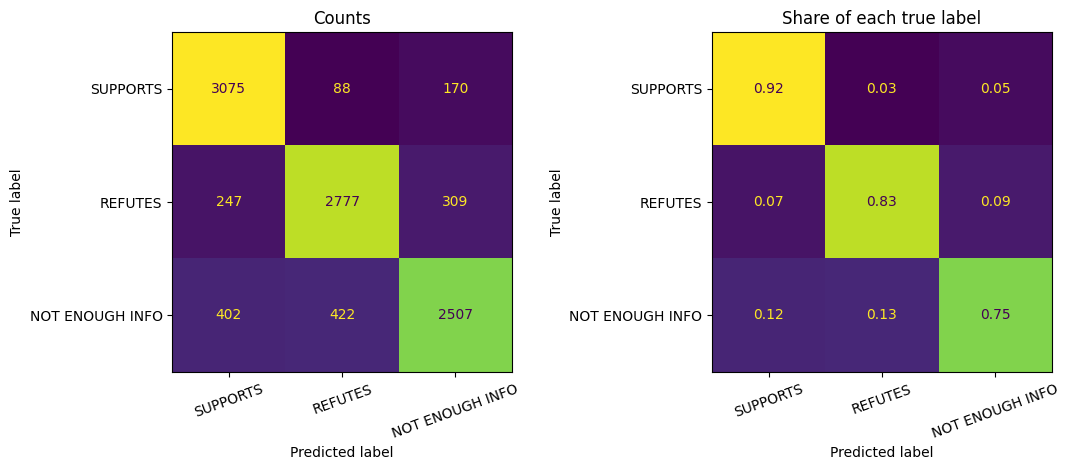

In [ ]:
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

pr, rc, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
majority_share = float(pd.Series(y_true).value_counts(normalize=True).max())
metrics = {'mode': MODE, 'n_val': int(len(y_true)), 'val_loss': float(val_loss),
           'val_accuracy': float(accuracy_score(y_true, y_pred)),
           'val_macro_precision': float(pr), 'val_macro_recall': float(rc), 'val_macro_f1': float(f1),
           'majority_class_baseline_accuracy': majority_share}
print(json.dumps(metrics, indent=2))

report = classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=LABELS, digits=4, zero_division=0)
print(report)
cm      = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
cm_norm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2], normalize='true')
print('Confusion matrix (rows = true, columns = predicted):'); print(cm)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=axes[0], xticks_rotation=20, colorbar=False)
axes[0].set_title('Counts')
ConfusionMatrixDisplay(cm_norm, display_labels=LABELS).plot(ax=axes[1], xticks_rotation=20, colorbar=False, values_format='.2f')
axes[1].set_title('Share of each true label')
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/confusion_matrix.png", dpi=150); plt.show()

json.dump(metrics, open(f"{CFG['out_dir']}/metrics.json", 'w'), indent=2)
open(f"{CFG['out_dir']}/classification_report.txt", 'w').write(report)
np.savetxt(f"{CFG['out_dir']}/confusion_matrix.csv", cm, fmt='%d', delimiter=',')

In [ ]:
probs = torch.softmax(logits, dim=-1).numpy()
res = val_pairs.copy()
res['pred_id'] = y_pred
res['pred'] = [id2label[i] for i in y_pred]
res['confidence'] = probs.max(1)
for i, name in id2label.items():
    res[f'p_{name}'] = probs[:, i]
lens = tok(list(res['claim']), list(res['evidence']))['input_ids']       # no truncation: true lengths
res['n_tokens'] = [len(x) for x in lens]
res['truncated'] = res['n_tokens'] > MAX_LEN
res['wrong'] = res['label_id'] != res['pred_id']

errors = res[res['wrong']].sort_values('confidence', ascending=False).copy()
errors['error_type'] = ''        # to be filled by hand (tags are listed in the roadmap, Stage 8)
errors['notes'] = ''
errors['reviewed_by'] = ''

errors.to_csv(f"{CFG['out_dir']}/errors.csv", index=False)
res.to_parquet(f"{CFG['out_dir']}/val_predictions.parquet", index=False)

print(f'error rate: {res.wrong.mean():.4f} | errors: {len(errors)} of {len(res)}')
print(pd.crosstab(res['label'], res['pred']))
print('\nError rate by evidence source:'); print(res.groupby('evidence_source')['wrong'].agg(['mean', 'size']))
print('\nError rate by number of evidence sentences:'); print(res.groupby('n_sent')['wrong'].agg(['mean', 'size']))
print('\nError rate when truncated vs not:'); print(res.groupby('truncated')['wrong'].agg(['mean', 'size']))
print('\nMean confidence by true label:'); print(res.groupby('label')['confidence'].mean())
print('\nSaved files:', sorted(os.listdir(CFG['out_dir'])))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (655 > 512). Running this sequence through the model will result in indexing errors


error rate: 0.1638 | errors: 1638 of 9997
pred             NOT ENOUGH INFO  REFUTES  SUPPORTS
label                                              
NOT ENOUGH INFO             2507      422       402
REFUTES                      309     2777       247
SUPPORTS                     170       88      3075

Error rate by evidence source:
                     mean  size
evidence_source                
gold             0.122112  6666
tfidf            0.247373  3331

Error rate by number of evidence sentences:
            mean  size
n_sent                
1       0.176744  7327
2       0.147780  1509
3       0.131148   488
4       0.090047   211
5       0.047619   105
6       0.112150   107
7       0.083333    48
8       0.162791    43
9       0.064516    31
10      0.000000    23
11      0.058824    17
12      0.214286    14
13      0.038462    26
14      0.000000     7
15      0.000000     5
16      0.125000     8
17      0.500000     2
18      0.000000    10
20      0.000000     3
21      0.

In [ ]:
def show_errors(df, n=10, true_label=None, pred_label=None, max_ev=400):
    d = df[df['wrong']]
    if true_label: d = d[d['label'] == true_label]
    if pred_label: d = d[d['pred'] == pred_label]
    d = d.sort_values('confidence', ascending=False).head(n)
    if d.empty:
        print('No errors match this filter.'); return
    for _, r in d.iterrows():
        print(f"id {r['id']} | TRUE: {r['label']} | PRED: {r['pred']} ({r['confidence']:.2f}) | tokens: {r['n_tokens']}")
        print('  CLAIM   :', r['claim'])
        print('  EVIDENCE:', r['evidence'][:max_ev]); print()

show_errors(res, n=5)

id 2521 | TRUE: REFUTES | PRED: NOT ENOUGH INFO (1.00) | tokens: 52
  CLAIM   : Akkineni Nageswara Rao plays in Daag.
  EVIDENCE: The film was later remade into the Telugu film Vichitra Jeevitham ( 1978 ) starring Akkineni Nageswara Rao , Vanisri , and Jayasudha .

id 144168 | TRUE: REFUTES | PRED: NOT ENOUGH INFO (1.00) | tokens: 48
  CLAIM   : Vanisri plays in Daag.
  EVIDENCE: The film was later remade into the Telugu film Vichitra Jeevitham ( 1978 ) starring Akkineni Nageswara Rao , Vanisri , and Jayasudha .

id 47000 | TRUE: REFUTES | PRED: NOT ENOUGH INFO (1.00) | tokens: 82
  CLAIM   : Vin Diesel is friends with Riddick.
  EVIDENCE: Actor Vin Diesel has played the title role in all of the Riddick-based films and video games so far . Produced by and starring Vin Diesel as the title character , Riddick is written and directed by David Twohy , who previously wrote and directed the first two installments , Pitch Black ( 2000 ) and The Chronicles of Riddick ( 2004 ) .

id 70812 | TRU

In [ ]:
def tag_summary(path):
    d = pd.read_csv(path).fillna('')
    tagged = d[d['error_type'].str.strip() != '']
    print(f'{len(tagged)} of {len(d)} errors tagged')
    if len(tagged):
        print(tagged['error_type'].value_counts())
        print(pd.crosstab(tagged['error_type'], tagged['label']))
    return tagged

_ = tag_summary(f"{CFG['out_dir']}/errors.csv")

0 of 1638 errors tagged


In [ ]:
import shutil
for p in [f'{ROOT}/models/_toy_model', f'{ROOT}/results/_toy', f'{ROOT}/data/processed/_toy_val_pairs.parquet']:
    if os.path.isdir(p):  shutil.rmtree(p)
    elif os.path.exists(p): os.remove(p)
print('models:', sorted(os.listdir(f'{ROOT}/models')), '| results:', sorted(os.listdir(f'{ROOT}/results')))

In [ ]:
import json, os
from google.colab import drive
drive.mount('/content/drive')
R = '/content/drive/MyDrive/fever_project/results'

SECONDS = 1038.1161      # train_runtime from the Cell 17 output of the training session
cfg = json.load(open(f'{R}/training_config.json'))
cfg.update(training_seconds_recorded=SECONDS, training_minutes_recorded=round(SECONDS / 60, 1),
           train_samples_per_second=280.215, segments=1, unfinished_segments=0,
           segment_status=['finished'],
           duration_note='Duration transcribed from the Cell 17 output; run1_segments.json on Drive still said running because its final write did not sync.')
json.dump(cfg, open(f'{R}/training_config.json', 'w'), indent=2)

segs = json.load(open(f'{R}/run1_segments.json'))
segs[-1].update(status='finished', seconds=SECONDS)
json.dump(segs, open(f'{R}/run1_segments.json', 'w'), indent=2)

drive.flush_and_unmount(); drive.mount('/content/drive')
print(json.load(open(f'{R}/training_config.json'))['training_minutes_recorded'], json.load(open(f'{R}/run1_segments.json'))[-1]['status'])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mounted at /content/drive
17.3 finished


In [ ]:
errs = pd.read_csv(f"{CFG['out_dir']}/errors.csv").fillna('')     # sorted by confidence, highest first

m3 = errs.head(30).copy()                                         # Member 3: the 30 most confident mistakes
rest = errs[~errs['id'].isin(m3['id'])]
m1 = rest[rest['label'].isin(['SUPPORTS', 'REFUTES'])].sample(min(30, (rest['label'] != 'NOT ENOUGH INFO').sum()), random_state=7).copy()
m2 = rest[rest['label'] == 'NOT ENOUGH INFO'].sample(min(30, (rest['label'] == 'NOT ENOUGH INFO').sum()), random_state=7).copy()

for who, df in [('member1', m1), ('member2', m2), ('member3', m3)]:
    df['reviewed_by'] = who
    keep = ['id', 'label', 'pred', 'confidence', 'n_sent', 'n_tokens', 'truncated', 'evidence_source',
            'claim', 'evidence', 'error_type', 'notes', 'reviewed_by']
    path = f"{CFG['out_dir']}/review_{who}.csv"
    df[keep].to_csv(path, index=False)
    print(who, len(df), 'rows ->', path)

assert len(set(m1['id']) | set(m2['id']) | set(m3['id'])) == len(m1) + len(m2) + len(m3), 'review sheets overlap'
print('error counts by true label in all errors:', errs['label'].value_counts().to_dict())

member1 30 rows -> /content/drive/MyDrive/fever_project/results/review_member1.csv
member2 30 rows -> /content/drive/MyDrive/fever_project/results/review_member2.csv
member3 30 rows -> /content/drive/MyDrive/fever_project/results/review_member3.csv
error counts by true label in all errors: {'NOT ENOUGH INFO': 824, 'REFUTES': 556, 'SUPPORTS': 258}


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

res = pd.read_parquet(f"{CFG['out_dir']}/val_predictions.parquet")        # written by Cell F
# 1) is the model less confident when it is wrong?
print('mean confidence | correct:', round(res.loc[~res.wrong, 'confidence'].mean(), 3),
      '| wrong:', round(res.loc[res.wrong, 'confidence'].mean(), 3))
bins = pd.cut(res['confidence'], [0, 0.5, 0.7, 0.9, 0.99, 1.0])
print(res.groupby(bins, observed=True)['wrong'].agg(error_rate='mean', n='size').round(3))

# 2) errors by evidence length quartile and true label
res['len_q'] = pd.qcut(res['n_tokens'], 4, labels=['Q1 short', 'Q2', 'Q3', 'Q4 long'])
print(res.pivot_table(index='len_q', columns='label', values='wrong', aggfunc='mean', observed=True).round(3))

# 3) how much do text-length features alone achieve? (trained on train_pairs, tested on val_pairs)
tr = pd.read_parquet(f'{ROOT}/data/processed/train_pairs.parquet')
def shape_feats(d):
    return np.c_[d['n_sent'], d['evidence'].str.split().str.len(), d['claim'].str.split().str.len()]
gb = HistGradientBoostingClassifier(max_iter=100, random_state=0).fit(shape_feats(tr), tr['label_id'])
p = gb.predict(shape_feats(val_pairs))
print('\nlength-only baseline on validation | accuracy:', round(accuracy_score(val_pairs['label_id'], p), 4),
      '| macro-F1:', round(f1_score(val_pairs['label_id'], p, average='macro'), 4))

# 4) descriptive only: claims containing a negation word (a heuristic, not a label)
neg = res['claim'].str.contains(r"\b(?:not|no|never|none|neither|nor)\b|n't", case=False, regex=True)
print('\nerror rate with negation word:', round(res.loc[neg, 'wrong'].mean(), 3), f'(n={int(neg.sum())})',
      '| without:', round(res.loc[~neg, 'wrong'].mean(), 3), f'(n={int((~neg).sum())})')
print(pd.crosstab(neg, res['label'], values=res['wrong'], aggfunc='mean').round(3))

# 5) read the confusions the numbers point to
for t, pr in [('REFUTES', 'SUPPORTS'), ('NOT ENOUGH INFO', 'SUPPORTS'), ('NOT ENOUGH INFO', 'REFUTES')]:
    print(f'\n===== TRUE {t} -> PREDICTED {pr} =====')
    show_errors(res, n=5, true_label=t, pred_label=pr)

mean confidence | correct: 0.936 | wrong: 0.8
             error_rate     n
confidence                   
(0.0, 0.5]        0.533   169
(0.5, 0.7]        0.462   902
(0.7, 0.9]        0.324  1398
(0.9, 0.99]       0.139  4182
(0.99, 1.0]       0.029  3346
label     NOT ENOUGH INFO  REFUTES  SUPPORTS
len_q                                       
Q1 short            0.220    0.149     0.086
Q2                  0.263    0.208     0.102
Q3                  0.295    0.185     0.067
Q4 long             0.214    0.127     0.057

length-only baseline on validation | accuracy: 0.3387 | macro-F1: 0.185

error rate with negation word: 0.111 (n=398) | without: 0.166 (n=9599)
label  NOT ENOUGH INFO  REFUTES  SUPPORTS
claim                                    
False            0.245    0.183     0.072
True             0.415    0.024     0.731

===== TRUE REFUTES -> PREDICTED SUPPORTS =====
id 137429 | TRUE: REFUTES | PRED: SUPPORTS (1.00) | tokens: 46
  CLAIM   : Murda Beatz was born in 1994.
  EVIDEN

In [ ]:
res = pd.read_parquet(f"{CFG['out_dir']}/val_predictions.parquet")

# 1) negation: counts per cell, not only rates
res['neg'] = res['claim'].str.contains(r"\b(?:not|no|never|none|neither|nor)\b|n't", case=False, regex=True)
print('negation x label, error rate and number of examples:')
print(res.pivot_table(index='neg', columns='label', values='wrong', aggfunc=['mean', 'size']).round(3))
print('\nwhat the model predicted:'); print(pd.crosstab([res['neg'], res['label']], res['pred']))
print('\nsupported claims with negation that were misclassified:')
for _, r in res[res['neg'] & (res['label'] == 'SUPPORTS') & res['wrong']].head(6).iterrows():
    print(f"  [{r['pred']} {r['confidence']:.2f}] {r['claim']}  ||  {r['evidence'][:160]}")

# 2) identical claim text carrying different labels inside validation
res['conflict_dup'] = res.groupby('claim')['label'].transform('nunique') > 1
print('\nrows whose claim text appears in validation with more than one label:', int(res['conflict_dup'].sum()))
print(res.groupby('conflict_dup')['wrong'].agg(error_rate='mean', n='size').round(3))

# 3) Member 2's NEI audit: show its structure and any short categorical columns (e.g. the judgement)
a = pd.read_csv(f'{ROOT}/results/nei_audit_train.csv')
print('\naudit file shape:', a.shape, '| columns:', list(a.columns))
for c in a.columns:
    if a[c].nunique(dropna=False) <= 8:
        print(c, '->', a[c].value_counts(dropna=False).to_dict())

negation x label, error rate and number of examples:
                 mean                             size                 
label NOT ENOUGH INFO REFUTES SUPPORTS NOT ENOUGH INFO REFUTES SUPPORTS
neg                                                                    
False           0.245   0.183    0.072            3290    3002     3307
True            0.415   0.024    0.731              41     331       26

what the model predicted:
pred                   NOT ENOUGH INFO  REFUTES  SUPPORTS
neg   label                                              
False NOT ENOUGH INFO             2483      408       399
      REFUTES                      304     2454       244
      SUPPORTS                     164       75      3068
True  NOT ENOUGH INFO               24       14         3
      REFUTES                        5      323         3
      SUPPORTS                       6       13         7

supported claims with negation that were misclassified:
  [REFUTES 0.87] Ed Wood is not about t

In [ ]:
errs = pd.read_csv(f"{CFG['out_dir']}/errors.csv").fillna('')
used = set()
for who in ['member1', 'member2', 'member3']:
    used |= set(pd.read_csv(f"{CFG['out_dir']}/review_{who}.csv")['id'])
pool = errs[~errs['id'].isin(used)]
rnd = pool.sample(30, random_state=11).copy()
rnd['reviewed_by'] = 'member3_random'
keep = ['id', 'label', 'pred', 'confidence', 'n_sent', 'n_tokens', 'truncated', 'evidence_source',
        'claim', 'evidence', 'error_type', 'notes', 'reviewed_by']
rnd[keep].to_csv(f"{CFG['out_dir']}/review_member3_random.csv", index=False)
print(len(rnd), 'rows saved | true-label mix:', rnd['label'].value_counts().to_dict())

from google.colab import drive
drive.flush_and_unmount(); drive.mount('/content/drive')
print(sorted(f for f in os.listdir(CFG['out_dir']) if f.startswith('review_')))

30 rows saved | true-label mix: {'NOT ENOUGH INFO': 15, 'REFUTES': 11, 'SUPPORTS': 4}
Mounted at /content/drive
['review_member1.csv', 'review_member2.csv', 'review_member3.csv', 'review_member3_random.csv']


In [ ]:
import glob
ALLOWED = ['evidence_incomplete', 'evidence_wrong', 'multi_sentence', 'truncated', 'nei_not_neutral',
           'ambiguous_claim', 'label_noise', 'model_limitation', 'class_imbalance_effect']
files = sorted(glob.glob(f'{ROOT}/results/tagged/review_*_tagged.csv'))
print('tagged files found:', [os.path.basename(f) for f in files])
assert files, 'No tagged files in results/tagged yet.'

allr = pd.concat([pd.read_csv(f).fillna('').assign(sheet=os.path.basename(f)) for f in files], ignore_index=True)
allr['error_type'] = allr['error_type'].astype(str).str.strip()
print('rows:', len(allr), '| tagged:', int((allr.error_type != '').sum()), '| duplicated ids across sheets:', int(allr['id'].duplicated().sum()))
bad = allr[(allr.error_type != '') & ~allr.error_type.isin(ALLOWED)]
print('rows with a tag outside the agreed list:', len(bad), bad.error_type.unique().tolist())

t = allr[allr.error_type != '']
print('\nAll reviewed errors (NOT a random sample of all errors):'); print(t.error_type.value_counts())
print(pd.crosstab(t.error_type, t.label))

# only the randomly drawn sheets can be read as a rough sample of the 1,638 errors
rnd = t[t.sheet.str.contains('member1|member2|member3_random')]
print('\nRandomly drawn sheets only:', len(rnd), 'errors'); print(rnd.error_type.value_counts())

t.to_csv(f'{ROOT}/results/errors_tagged_all.csv', index=False)
from google.colab import drive
drive.flush_and_unmount(); drive.mount('/content/drive')
print(os.path.exists(f'{ROOT}/results/errors_tagged_all.csv'))

tagged files found: ['review_member1_tagged.csv', 'review_member2_tagged.csv', 'review_member3_random_tagged.csv', 'review_member3_tagged.csv']
rows: 120 | tagged: 120 | duplicated ids across sheets: 0
rows with a tag outside the agreed list: 0 []

All reviewed errors (NOT a random sample of all errors):
error_type
model_limitation       41
evidence_incomplete    39
nei_not_neutral        15
label_noise            10
evidence_wrong          9
truncated               4
ambiguous_claim         2
Name: count, dtype: int64
label                NOT ENOUGH INFO  REFUTES  SUPPORTS
error_type                                             
ambiguous_claim                    0        1         1
evidence_incomplete               21       12         6
evidence_wrong                     9        0         0
label_noise                        0        7         3
model_limitation                   3       31         7
nei_not_neutral                   15        0         0
truncated                  

In [ ]:
from datasets import load_dataset
raw = load_dataset('parquet', data_files={'validation': 'hf://datasets/fever/fever@refs/convert/parquet/v1.0/paper_dev/*.parquet'})['validation'].to_pandas()
claims = ['Luke Cage did not team up with Iron Fist.', 'Tim Roth was not born on May 14th, 1961.',
          'Ed Wood is not about the eponymous filmmaker.', 'Angelsberg is not located directly next to an ocean.']
view = raw[raw['claim'].isin(claims)][['id', 'claim', 'label', 'evidence_wiki_url', 'evidence_sentence_id']]
print(view.sort_values('id').to_string())

v1.0/paper_dev/0000.parquet: reconstructing file:   0%|          |  0.00B /  757kB            

v1.0/paper_dev/0000.parquet: downloading bytes:           |  0.00B            

Generating validation split: 0 examples [00:00, ? examples/s]

          id                                                 claim     label       evidence_wiki_url  evidence_sentence_id
13173   1667         Ed Wood is not about the eponymous filmmaker.  SUPPORTS  Ed_Wood_-LRB-film-RRB-                     1
13174   1667         Ed Wood is not about the eponymous filmmaker.  SUPPORTS  Ed_Wood_-LRB-film-RRB-                    -1
18401  15155             Luke Cage did not team up with Iron Fist.  SUPPORTS               Luke_Cage                     6
12864  35575              Tim Roth was not born on May 14th, 1961.  SUPPORTS                Tim_Roth                    -1
11767  46705  Angelsberg is not located directly next to an ocean.  SUPPORTS              Angelsberg                    -1
11768  46705  Angelsberg is not located directly next to an ocean.  SUPPORTS              Luxembourg                    -1


In [ ]:
from datasets import load_dataset
base = 'hf://datasets/fever/fever@refs/convert/parquet/v1.0'
raw = load_dataset('parquet', data_files={'train': f'{base}/train/*.parquet', 'validation': f'{base}/paper_dev/*.parquet'})

per = {}
for split in ['train', 'validation']:
    d = raw[split].to_pandas()
    d = d[d.label != 'NOT ENOUGH INFO'].copy()
    d['unk'] = d['evidence_sentence_id'] == -1
    g = d.groupby('id').agg(label=('label', 'first'), all_unk=('unk', 'all'), any_unk=('unk', 'any'), rows=('unk', 'size'))
    per[split] = g
    print(f'\n{split}: SUPPORTS/REFUTES claims = {len(g)}')
    print('claims where EVERY pointer is -1:', int(g.all_unk.sum()), '| claims with at least one -1:', int(g.any_unk.sum()))
    print(g.groupby('label')[['all_unk', 'any_unk']].sum())

res = pd.read_parquet(f"{CFG['out_dir']}/val_predictions.parquet")
m = res.merge(per['validation'][['all_unk', 'any_unk']].reset_index(), on='id', how='left')
m[['all_unk', 'any_unk']] = m[['all_unk', 'any_unk']].fillna(False).astype(bool)
sr = m[m['label'] != 'NOT ENOUGH INFO']
print('\nvalidation error rate for SUPPORTS/REFUTES claims, by whether the evidence pointer is unknown:')
print(sr.groupby(['label', 'all_unk'])['wrong'].agg(error_rate='mean', n='size').round(3))
print('\nmedian n_sent for these claims:', sr.groupby('all_unk')['n_sent'].median().to_dict())

v1.0/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 12.4MB            

v1.0/train/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]


train: SUPPORTS/REFUTES claims = 109810
claims where EVERY pointer is -1: 32219 | claims with at least one -1: 56254
          all_unk  any_unk
label                     
REFUTES     10106    16499
SUPPORTS    22113    39755

validation: SUPPORTS/REFUTES claims = 6666
claims where EVERY pointer is -1: 2557 | claims with at least one -1: 3907
          all_unk  any_unk
label                     
REFUTES      1398     2074
SUPPORTS     1159     1833

validation error rate for SUPPORTS/REFUTES claims, by whether the evidence pointer is unknown:
                  error_rate     n
label    all_unk                  
REFUTES  False         0.165  1935
         True          0.170  1398
SUPPORTS False         0.085  2174
         True          0.064  1159

median n_sent for these claims: {False: 1.0, True: 1.0}


/tmp/ipykernel_3238/340085441.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  m[['all_unk', 'any_unk']] = m[['all_unk', 'any_unk']].fillna(False).astype(bool)


In [ ]:
import collections
parts = []
for k in [1, 2, 3]:
    d = pd.read_csv(f'{ROOT}/results/tagged/nei_audit_m{k}.csv').set_index('id')
    parts.append(d[f'judgement_m{k}'].astype(str).str.strip().str.lower().rename(f'm{k}'))
j = pd.concat(parts, axis=1)
assert j.notna().all().all() and j.isin(['neither', 'supports', 'refutes']).all().all(), 'blank or invalid judgements'
maj = j.apply(lambda r: collections.Counter(r).most_common(1)[0][0], axis=1)
agree = (j.nunique(axis=1) == 1)
print('pairs judged:', len(j), '| all three agree:', int(agree.sum()))
print('majority judgement:', maj.value_counts().to_dict())
print('share NOT neutral (majority):', round(float((maj != 'neither').mean()), 3))
print('share NOT neutral per judge:', {c: round(float((j[c] != 'neither').mean()), 3) for c in j})

pairs judged: 50 | all three agree: 50
majority judgement: {'neither': 44, 'refutes': 5, 'supports': 1}
share NOT neutral (majority): 0.12
share NOT neutral per judge: {'m1': 0.12, 'm2': 0.12, 'm3': 0.12}


In [ ]:
flat = pd.read_parquet(f'{ROOT}/data/processed/claims_val_flat.parquet')
gold = pd.read_parquet(f'{ROOT}/data/processed/gold_val.parquet')
print('claims_val_flat columns:', list(flat.columns), '| rows:', len(flat))
print('gold_val columns      :', list(gold.columns), '| rows:', len(gold))
ids = [1667, 15155, 35575, 46705]       # Ed Wood, Luke Cage, Tim Roth, Angelsberg
pd.set_option('display.width', 250, 'display.max_colwidth', 120)
print(flat[flat['id'].isin(ids)].to_string())
print(gold[gold['id'].isin(ids)][['id', 'claim', 'label', 'n_sent']].to_string())

claims_val_flat columns: ['id', 'label', 'claim', 'evidence_annotation_id', 'evidence_id', 'evidence_wiki_url', 'evidence_sentence_id'] | rows: 18999
gold_val columns      : ['id', 'claim', 'evidence', 'label', 'n_sent', 'evidence_source'] | rows: 6666
          id     label                                                 claim  evidence_annotation_id  evidence_id       evidence_wiki_url  evidence_sentence_id
11767  46705  SUPPORTS  Angelsberg is not located directly next to an ocean.                   63034        73731              Angelsberg                     0
11768  46705  SUPPORTS  Angelsberg is not located directly next to an ocean.                   63034        73731              Luxembourg                     0
12864  35575  SUPPORTS              Tim Roth was not born on May 14th, 1961.                   51961        61809                Tim_Roth                     0
13173   1667  SUPPORTS         Ed Wood is not about the eponymous filmmaker.                   17409       

In [ ]:
from datasets import load_dataset
base = 'hf://datasets/fever/fever@refs/convert/parquet/v1.0'
raw = load_dataset('parquet', data_files={'train': f'{base}/train/*.parquet', 'validation': f'{base}/paper_dev/*.parquet'})

def pointers(d, fix):
    d = d[d['label'] != 'NOT ENOUGH INFO'].copy()
    sid = d['evidence_sentence_id'].to_numpy().copy()
    if fix:
        sid[(d['evidence_wiki_url'] != '').to_numpy() & (sid == -1)] = 0
    d['pair'] = list(zip(d['evidence_wiki_url'], sid.tolist()))
    return d.groupby('id')['pair'].agg(lambda s: tuple(sorted(set(s))))

for split, flatname in [('validation', 'claims_val_flat.parquet'), ('train', 'claims_train_flat.parquet')]:
    hf   = pointers(raw[split].to_pandas(), fix=True)
    flat = pointers(pd.read_parquet(f'{ROOT}/data/processed/{flatname}'), fix=False)
    both = hf.index.intersection(flat.index)
    diff = [i for i in both if hf[i] != flat[i]]
    print(f'{split}: HF claims {len(hf)} | flat claims {len(flat)} | compared {len(both)} | differing pointers: {len(diff)}')
    for i in diff[:3]:
        print('  id', i, '| HF corrected:', hf[i], '| flat:', flat[i])

validation: HF claims 6666 | flat claims 6666 | compared 6666 | differing pointers: 0
train: HF claims 109810 | flat claims 109810 | compared 109810 | differing pointers: 0
